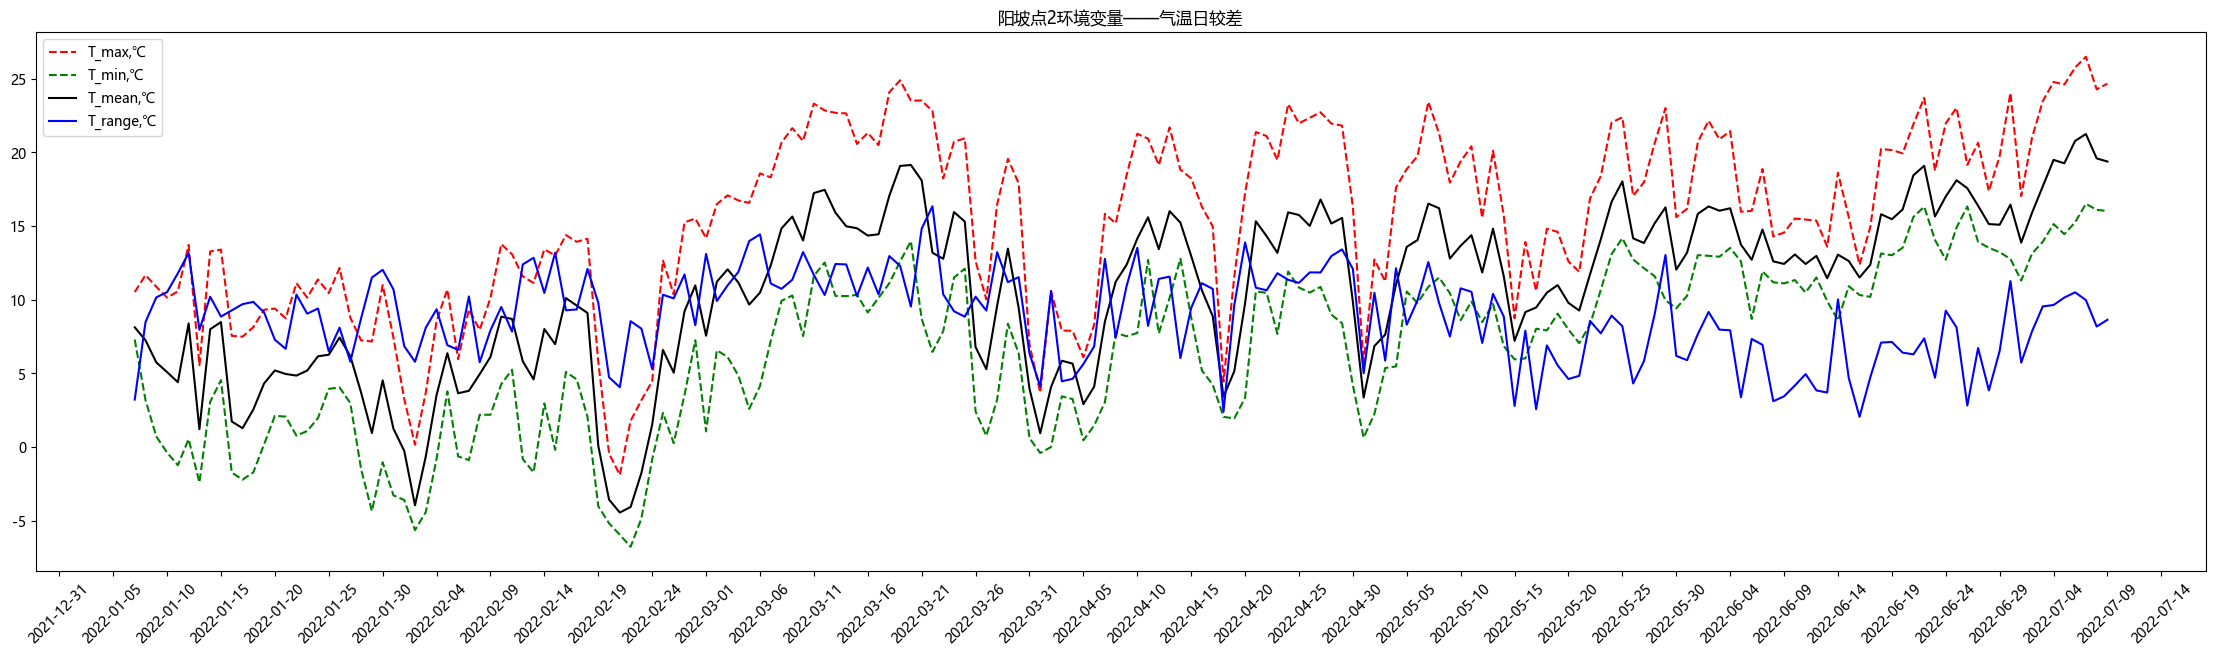

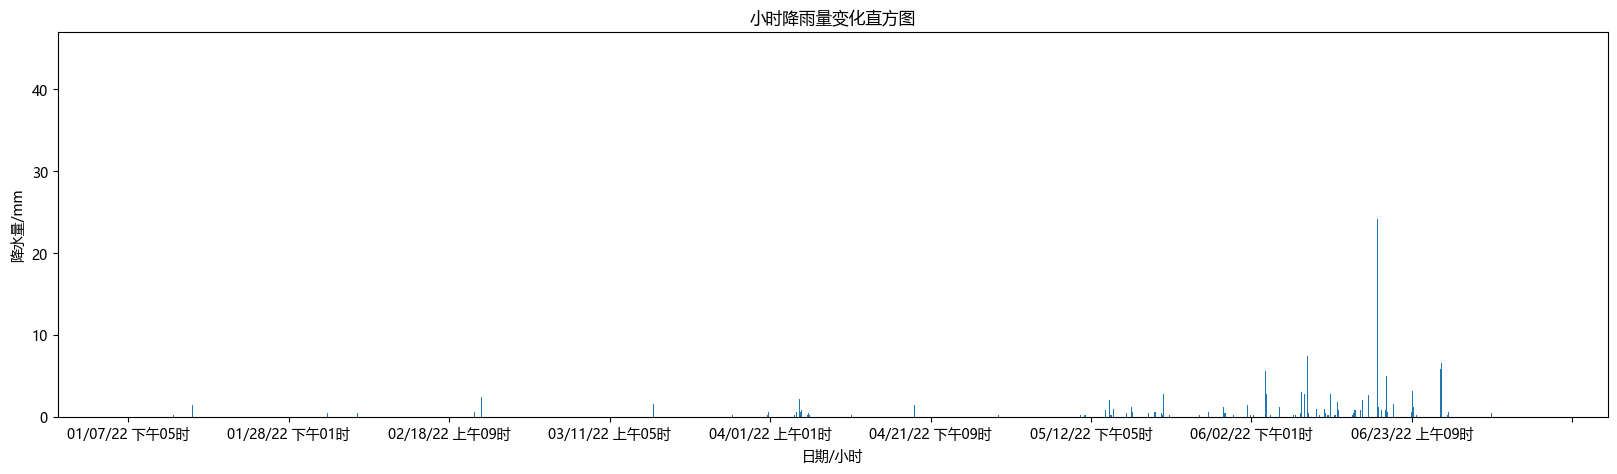

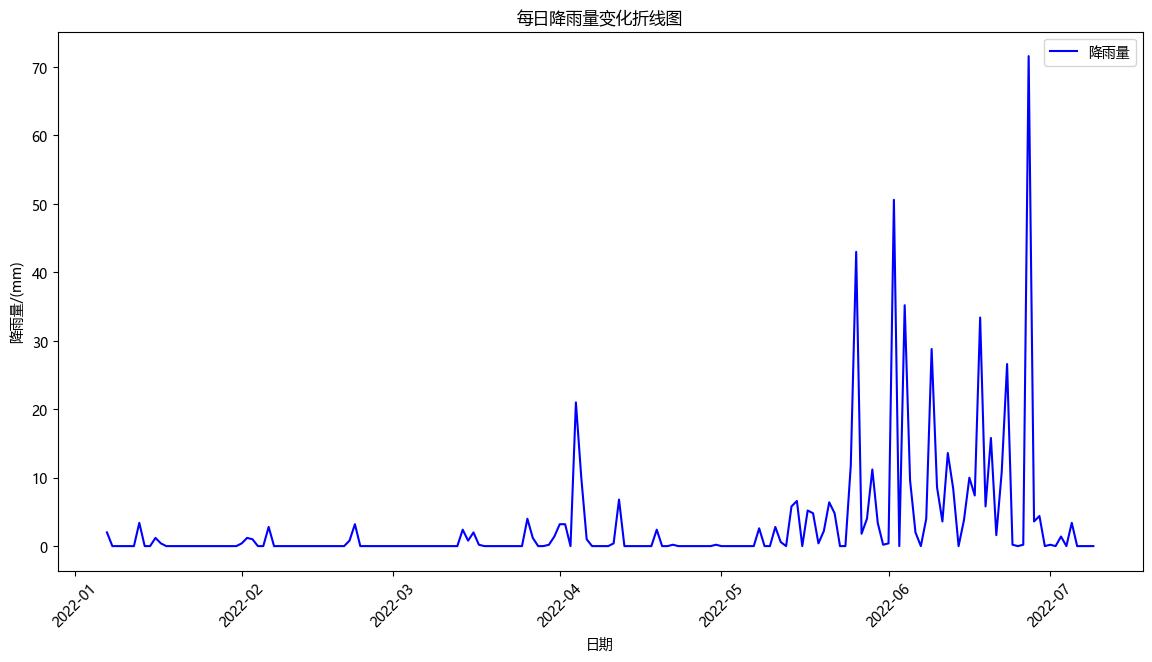

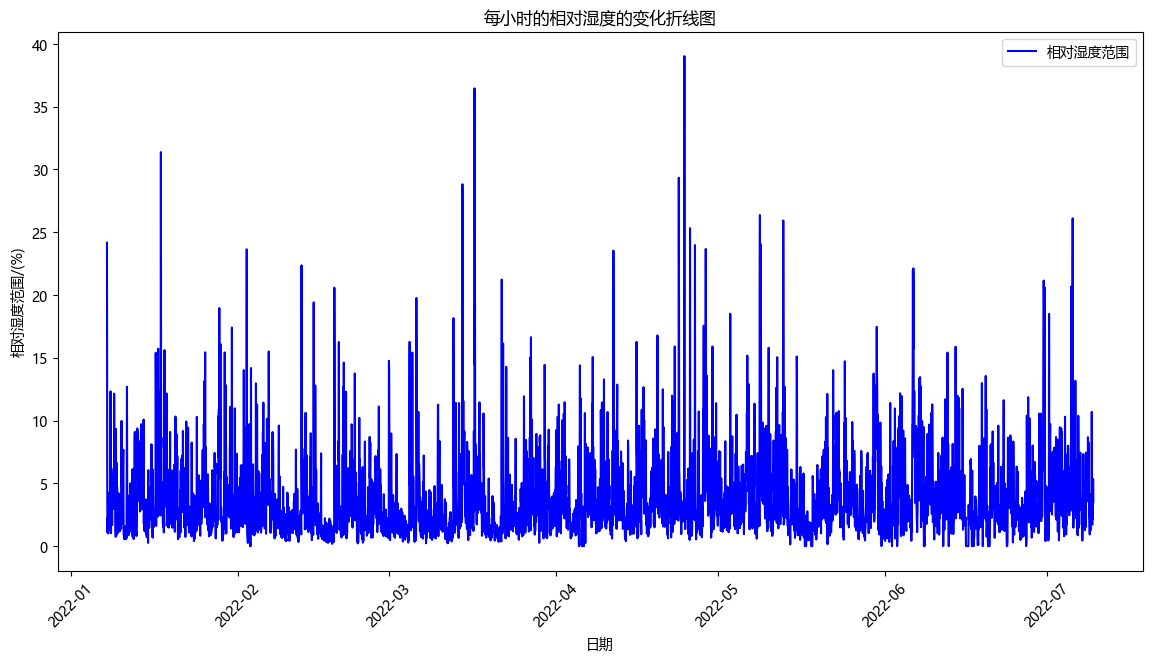

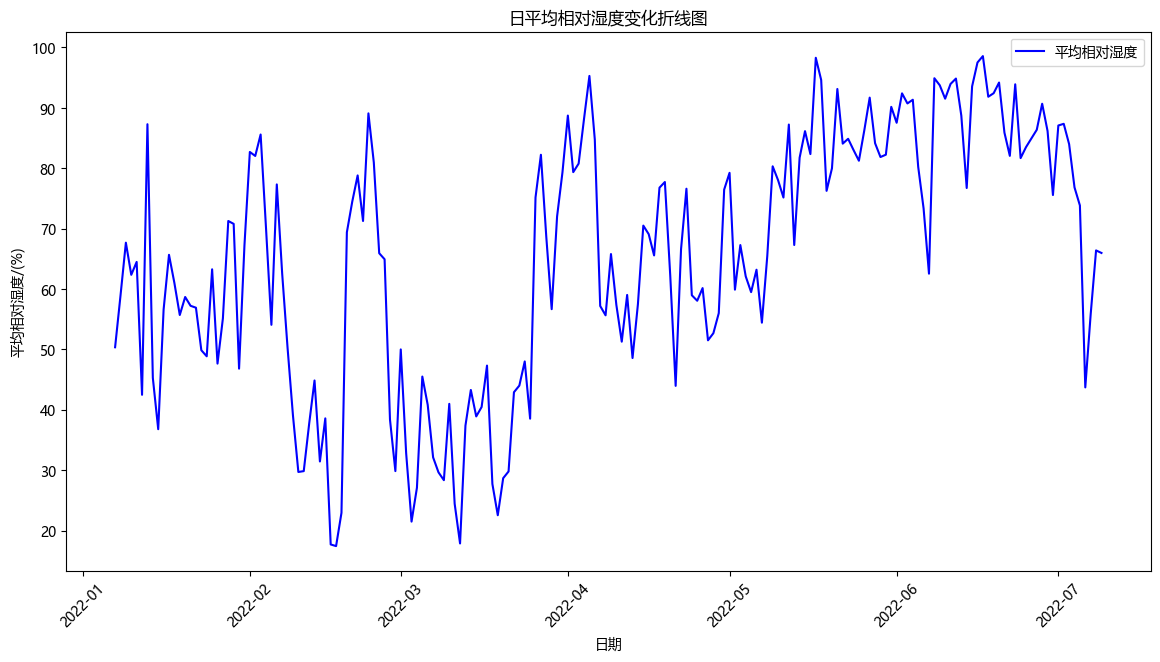

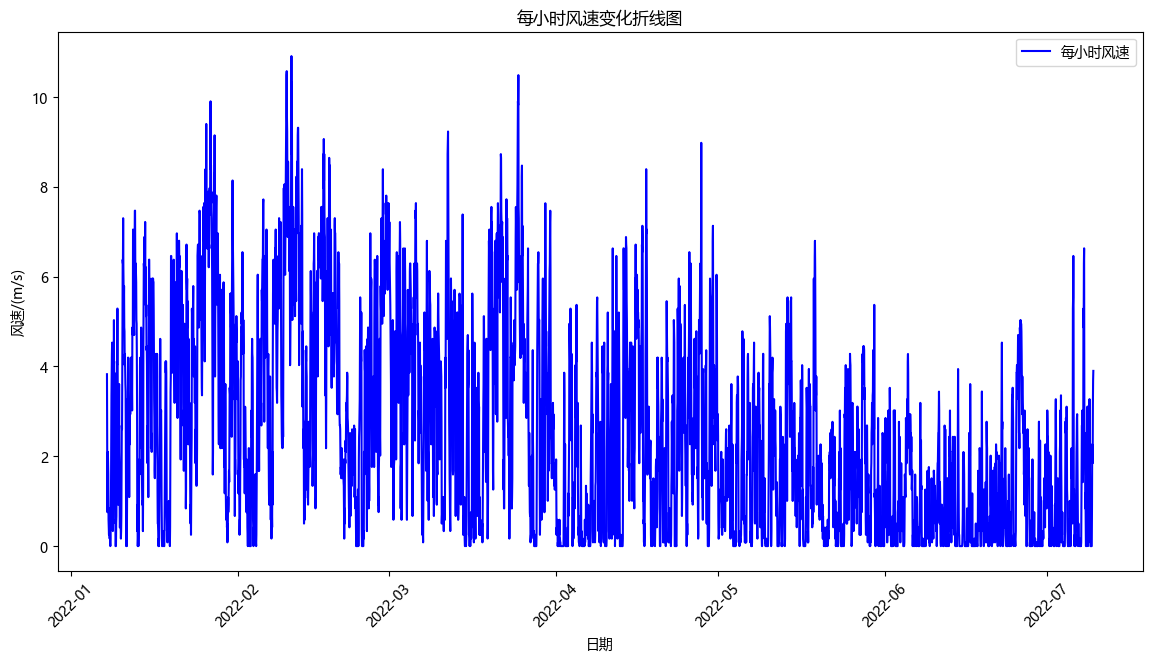

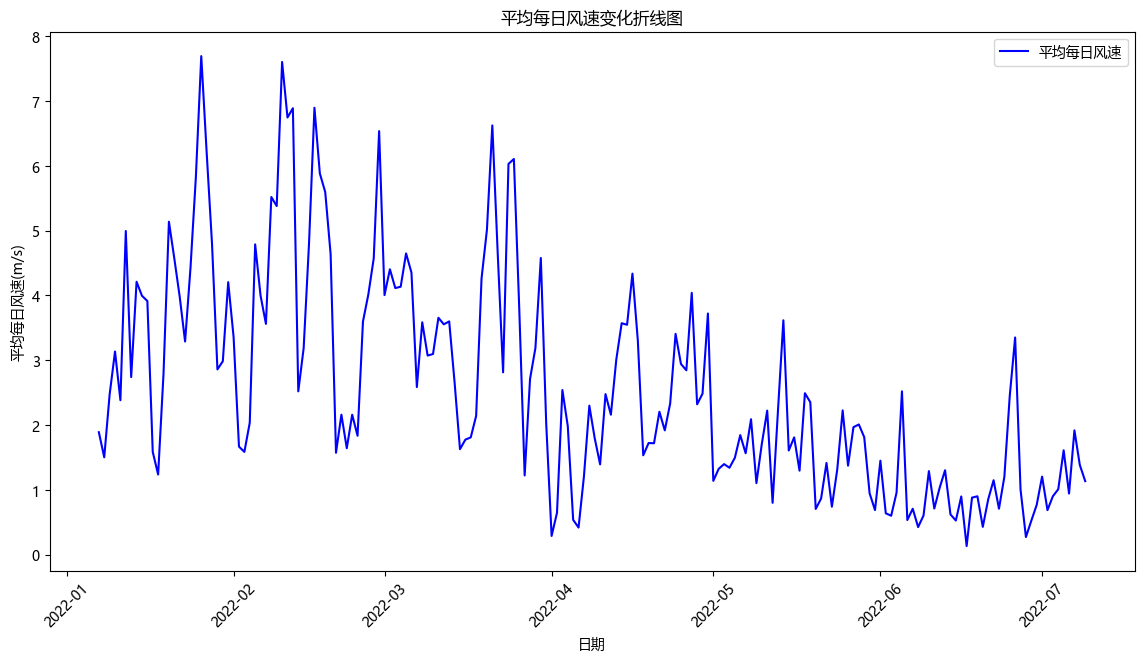

In [51]:
# coding:gbk
from datetime import timedelta, datetime
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.dates as mdates
import numpy as np
from pylab import mpl
from matplotlib import pyplot as plt, ticker
# 读取数据
data = pd.read_csv('YangPo#2.csv', header=0, encoding='gbk',
                   names=['Index', 'Date Time', 'Rain', 'Wind Speed', 'Gust Speed',
                          'Wind Direction', 'Temperature', 'RH', 'DewPt'])
dataTime = data['Date Time']

# matplotlib下显示中文的方法
plt.rcParams['font.sans-serif'] = ['KaiTi']  # 指定默认字体(楷体)
plt.rcParams['axes.unicode_minus'] = False  # 解决保存图像时负号'-'显示为方块的问题
mpl.rcParams['font.sans-serif'] = ['Microsoft YaHei'] # 指定默认字体：解决plot不能显示中文问题

# 将时间12进制变成24进制
def tz_time_24(s):
    if '上午' in s:
        dt = datetime.strptime(s, "%m/%d/%Y 上午%H时%M分%S秒")
        if '上午12时' in s:
            dt -= timedelta(hours=12)
        return dt
    if '下午' in s:
        dt = datetime.strptime(s, "%m/%d/%Y 下午%H时%M分%S秒")
        if '下午12时' not in s:
            dt += timedelta(hours=12)
        return dt

# 获取标准的日历时间
def new_Etalon_time():
    day_hour = [tz_time_24(index.replace('/22 ', '/2022 ')) for index in dataTime]
    data['Date Time'] = pd.to_datetime(day_hour, format='%Y-%m-%d %H:%M:%S')
    return data['Date Time']

data['Date Time'] = new_Etalon_time()
data.set_index('Date Time', inplace=True)

# 提取温度相关列
temperature_data = data[['Temperature']]

# 计算每日温度统计值
hour_temperature_Statistics = temperature_data.resample('D').agg({'Temperature': ['max', 'min', 'mean']})
hour_temperature_Statistics['Temperature Range'] = hour_temperature_Statistics['Temperature']['max'] - \
                                                   hour_temperature_Statistics['Temperature']['min']
# 绘制温度变化折线图
plt.figure(figsize=(28, 7))
plt.plot(hour_temperature_Statistics.index, hour_temperature_Statistics['Temperature']['max'],
         label='T_max,℃', c='red', linestyle='--')
plt.plot(hour_temperature_Statistics.index, hour_temperature_Statistics['Temperature']['min'],
         label='T_min,℃', c='green', linestyle='--')
plt.plot(hour_temperature_Statistics.index, hour_temperature_Statistics['Temperature']['mean'],
         label='T_mean,℃', c='black')
plt.plot(hour_temperature_Statistics.index, hour_temperature_Statistics['Temperature Range'],
         label='T_range,℃', c='blue')
plt.title('阳坡点2环境变量——气温日较差')
plt.legend()

# 设置x轴刻度密度
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=5))  # 每天一个刻度
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))  # 设置日期格式

plt.xticks(rotation=45)
plt.show()

# delimiter是分隔符，skiprows是跳过前n行，usecols是使用的列数，例子中读取的是3,4列。
data = np.loadtxt(open("YangPo#2.csv", "rb"), delimiter=',', skiprows=1, dtype=list,
                  encoding="gbk")
rain_sum = 0

date = [data[0][1][0:14]]
rainSum = []

for i in data:
    if i[1][0:14] not in date:
        date.append(i[1][0:14])
        rainSum.append(rain_sum)
        rain_sum = float(i[2])
    if i[2] != "":
        rain_sum = rain_sum + float(i[2])
rainSum.append(rain_sum)

fig = plt.figure(figsize=(20, 5))
ax = fig.add_subplot(111)
ax.bar(date, rainSum)
tick_spacing = 500  # 通过修改tick_spacing的值可以修改x轴的密度
ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
plt.title("小时降雨量变化直方图")
plt.xlabel("日期/小时")
plt.ylabel("降水量/mm")
plt.show()

data = pd.read_csv('YangPo#2.csv', header=0, encoding='gbk',
                   names=['Index', 'Date Time', 'Rain', 'Wind Speed', 'Gust Speed',
                          'Wind Direction', 'Temperature', 'RH', 'DewPt'])
dataTime = data['Date Time']

data['Date Time'] = new_Etalon_time()  # 得到pandas时间格式

# 设置日期时间列为索引
data.set_index('Date Time', inplace=True)
rain_data = data[['Rain']]
daily_rain_stats = rain_data.resample('D').sum()

# 绘制折线图
plt.figure(figsize=(14, 7))
plt.plot(daily_rain_stats.index, daily_rain_stats['Rain'], c='blue', label='降雨量')
plt.xlabel('日期')
plt.ylabel('降雨量/(mm)')
plt.title('每日降雨量变化折线图')
plt.xticks(rotation=45)
plt.legend()
plt.show()

data['Date Time'] = new_Etalon_time()  # 得到pandas时间格式

# 设置日期时间列为索引
data.set_index('Date Time', inplace=True)

rh_data = data[['RH']]

# 计算每小时相对湿度统计值
hour_rh_Statistics = rh_data.resample('H').agg({'RH': ['max', 'min']})
hour_rh_Statistics['RH Range'] = hour_rh_Statistics['RH']['max'] - hour_rh_Statistics['RH']['min']

# 绘制折线图
plt.figure(figsize=(14, 7))
plt.plot(hour_rh_Statistics.index, hour_rh_Statistics['RH Range'], c='blue', label='相对湿度范围')
plt.xlabel('日期')
plt.ylabel('相对湿度范围/(%)')
plt.title('每小时的相对湿度的变化折线图')
plt.xticks(rotation=45)
plt.legend()
plt.show()

# 提取并绘制每小时相对湿度统计值
rh_data = data[['RH']]
hour_rh_Statistics = rh_data.resample('H').agg({'RH': ['max', 'min']})
hour_rh_Statistics['RH Range'] = hour_rh_Statistics['RH']['max'] - hour_rh_Statistics['RH']['min']
daily_rh_mean = rh_data.resample('D').mean()
plt.figure(figsize=(14, 7))
plt.plot(daily_rh_mean.index, daily_rh_mean['RH'], c='blue', label='平均相对湿度')
plt.xlabel('日期')
plt.ylabel('平均相对湿度/(%)')
plt.title('日平均相对湿度变化折线图')
plt.xticks(rotation=45)
plt.legend()
plt.show()

# 提取并绘制每小时风速统计值
wind_speed_data = data[['Wind Speed']]
hour_wind_speed_mean = wind_speed_data.resample('H').mean()
plt.figure(figsize=(14, 7))
plt.plot(hour_wind_speed_mean.index, hour_wind_speed_mean['Wind Speed'], c='blue', label='每小时风速')
plt.xlabel('日期')
plt.ylabel('风速/(m/s)')
plt.title('每小时风速变化折线图')
plt.xticks(rotation=45)
plt.legend()
plt.show()

# 提取并绘制每日风速统计值
daily_wind_speed_mean = wind_speed_data.resample('D').mean()
plt.figure(figsize=(14, 7))
plt.plot(daily_wind_speed_mean.index, daily_wind_speed_mean['Wind Speed'], c='blue', label='平均每日风速')
plt.xlabel('日期')
plt.ylabel('平均每日风速(m/s)')
plt.title('平均每日风速变化折线图')
plt.xticks(rotation=45)
plt.legend()
plt.show()


检查 每小时温度变化
异常值数量: 0
--------------------------------------------------


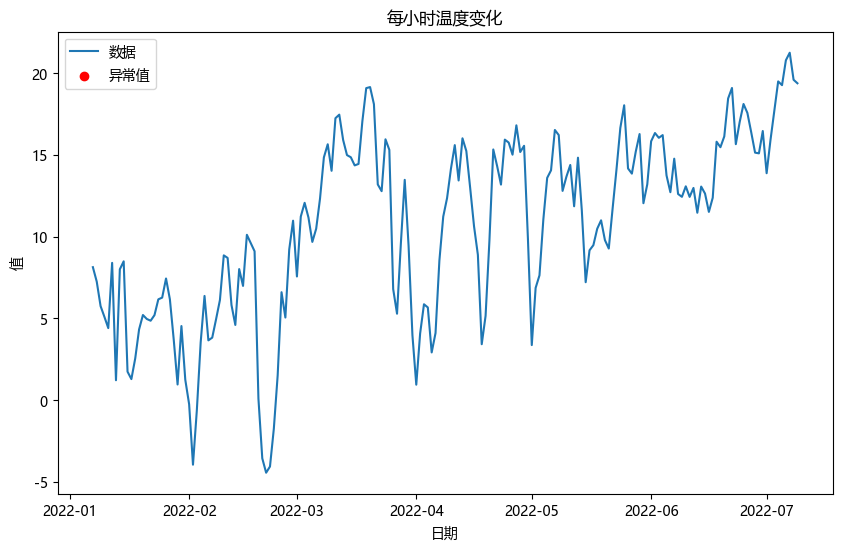

检查 每小时降雨量变化
异常值数量: 972
--------------------------------------------------


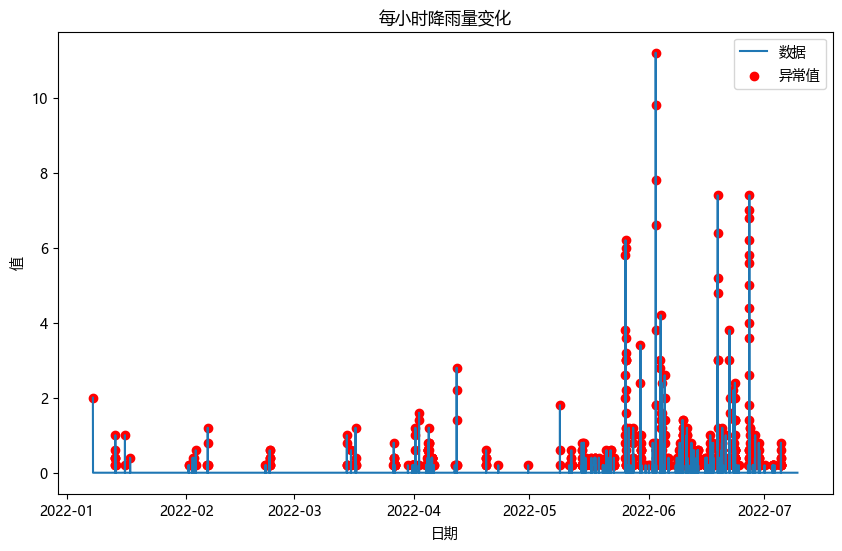

检查 日降雨量变化
异常值数量: 25
--------------------------------------------------


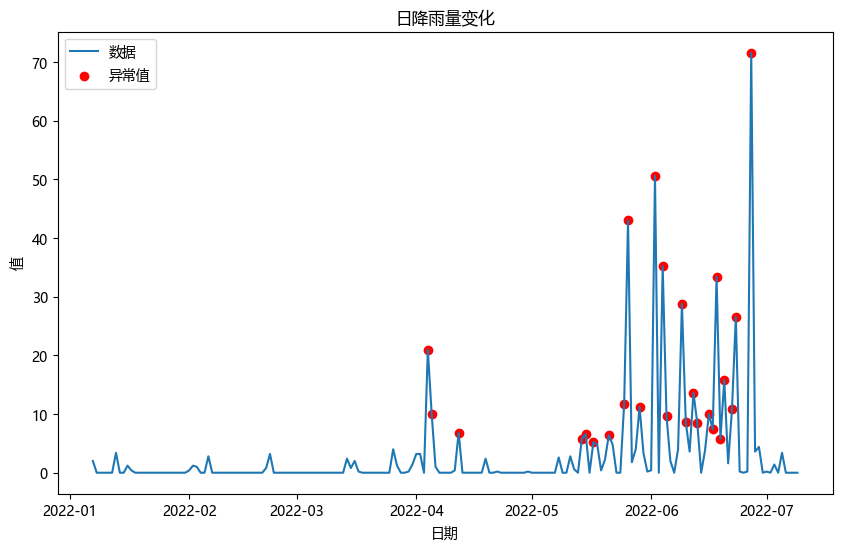

检查 每小时相对湿度变化
异常值数量: 235
--------------------------------------------------


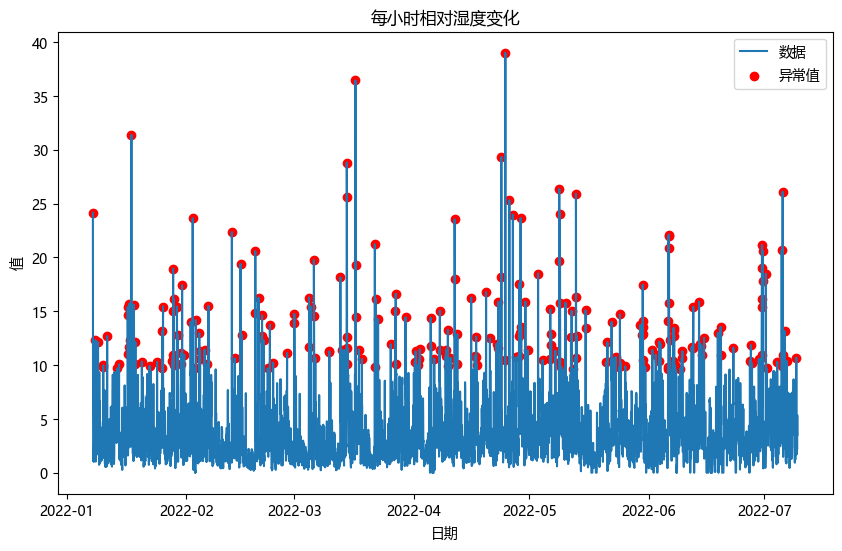

检查 每日相对湿度变化
异常值数量: 0
--------------------------------------------------


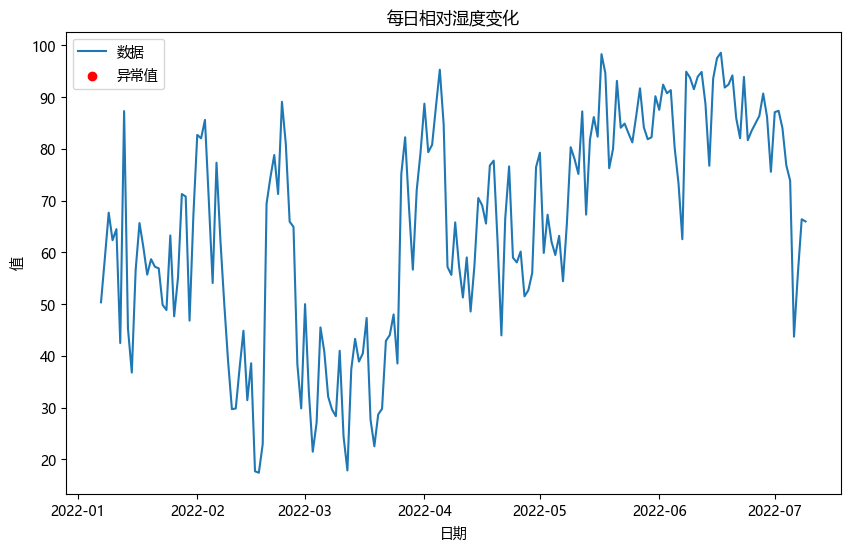

检查 每小时风速变化
异常值数量: 9
--------------------------------------------------


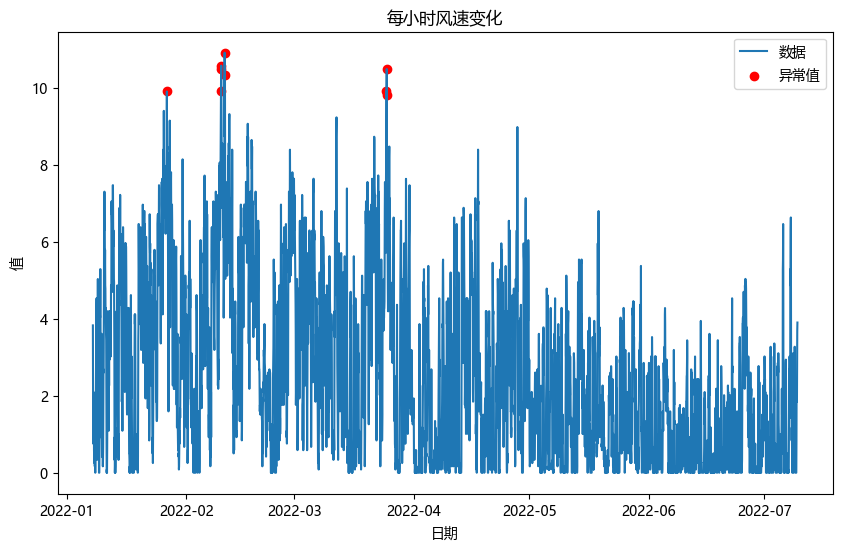

检查 每日风速变化
异常值数量: 2
--------------------------------------------------


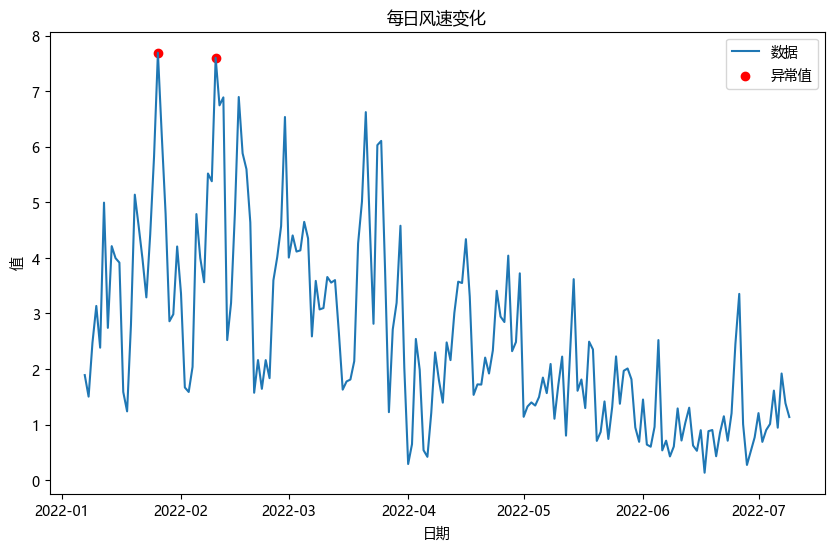

In [57]:
# 导入必要的模块
import numpy as np
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt

# 定义检测正态分布的函数
def is_normal_distribution(data):
    mean = data.mean()
    std = data.std()
    return stats.kstest(data, 'norm', (mean, std)).pvalue >= 0.05

# 定义异常值检测函数
def outlier_detection(data, is_normal):
    mean = data.mean()
    std = data.std()
    if is_normal:
        outliers = data[np.abs(data - mean) > 3 * std]
    else:
        q1 = data.quantile(0.25)
        q3 = data.quantile(0.75)
        iqr = q3 - q1
        lower_tail = q1 - 1.5 * iqr
        upper_tail = q3 + 1.5 * iqr
        outliers = data[(data < lower_tail) | (data > upper_tail)]
    return outliers

# 数据可视化函数
def visualize_data(data, title):
    plt.figure(figsize=(10, 6))
    plt.plot(data, label='数据')
    outliers = outlier_detection(data, is_normal_distribution(data))
    plt.scatter(outliers.index, outliers, color='red', label='异常值')
    plt.title(title)
    plt.xlabel('日期')
    plt.ylabel('值')
    plt.legend()
    plt.show()

# 定义要检查的所有数据集和对应的名称
datasets = [
    (hour_temperature_Statistics['Temperature']['mean'], '每小时温度变化'),
    (rain_data['Rain'], '每小时降雨量变化'),
    (daily_rain_stats['Rain'], '日降雨量变化'),
    (hour_rh_Statistics['RH Range'], '每小时相对湿度变化'),
    (daily_rh_mean['RH'], '每日相对湿度变化'),
    (hour_wind_speed_mean['Wind Speed'], '每小时风速变化'),
    (daily_wind_speed_mean['Wind Speed'], '每日风速变化')
]

# 逐个数据集进行检测和可视化
for data, title in datasets:
    print(f"检查 {title}")
    data_series = pd.Series(data)
    is_normal = is_normal_distribution(data_series)
    outliers = outlier_detection(data_series, is_normal)
    print(f"异常值数量: {len(outliers)}")
    print("-" * 50)
    visualize_data(data_series, title)
